# B5_praproses: Evaluasi Praktikum P1-P4 Computer Vision (SIMUTEH)
**Nama:** Rian | **NIM:** 2330511025 | **SEED:** 1025 | **Kelas:** 6A

Membutuhkan dataset dari B1 dan `src/praproses.py`. Mengintegrasikan praproses, evaluasi KB, uji bercak palsu, justifikasi, serta P5.1 sampai P5.5.

> Angka pada teks jawaban berasal dari satu kali jalan dengan SEED 1025. Nilai KB dan PSNR deterministik; **waktu (ms)** bergantung mesin, jadi cocokkan dengan keluaran milikmu.

## Bagian 5. Integrasi: Rangkaian Praproses SIMUTEH

In [1]:
import os, sys
# Jalankan dari folder notebook/ di dalam repository (jalur file selalu diawali ../).
if os.path.basename(os.getcwd()) != "notebook":
    cand = "/content/simuteh-2330511025/notebook"
    if os.path.exists(cand): os.chdir(cand)
    else: raise SystemExit("Buka notebook ini dari folder notebook/ di repository (di Colab: git clone repo-mu dahulu, lalu %cd simuteh-2330511025/notebook).")
sys.path.append("../src")
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd, time
from matplotlib.patches import FancyBboxPatch
from utils_cv import baca, tampil, kontras_bercak, statistik
if not os.path.exists("../data/sintetis/label.csv"):
    raise SystemExit("Dataset belum ada. Jalankan B1_lingkungan.ipynb dahulu (atau: cd .. lalu python src/buat_dataset_sintetis.py).")
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
print("Folder kerja:", os.getcwd(), "| citra:", len(label))

Folder kerja: /tmp/repo/simuteh-2330511025/notebook | citra: 60


### Langkah 5.1 Modul `src/praproses.py`
Modul sudah ditulis oleh sel `%%writefile` di Bagian 1 dengan lima langkah: (1) ubah ukuran `INTER_AREA` dengan rasio aspek tetap, (2) koreksi gamma lewat LUT, (3) CLAHE hanya di kanal V (HSV), (4) penapis derau (rerata/Gaussian/median), (5) *unsharp masking* opsional. Urutan mengikuti Gambar 5.

### Langkah 5.2 Evaluasi kuantitatif (Kode 5.2)
Kanal terpilih: **R** (indeks BGR 2), berdasarkan Bagian 2 (P2.2). Saya membandingkan beberapa kandidat parameter pada 40 citra berbercak, lalu memilih parameter final.

In [2]:
from praproses import praproses, simpan_param
KANAL = 2   # R, kanal terbaik Bagian 2
label = pd.read_csv("../data/sintetis/label.csv")
def evaluasi(param, kelas_tolak="sehat"):
    r = []
    for _, d in label[label.kelas != kelas_tolak].iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        a = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0); b_ = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        o = praproses(im, param)
        r.append([d.kondisi_cahaya, kontras_bercak(im[:, :, KANAL], a, b_), kontras_bercak(o[:, :, KANAL], a, b_)])
    t = pd.DataFrame(r, columns=["kondisi", "KB_sebelum", "KB_sesudah"]).groupby("kondisi").mean().loc[URUT]
    t["Perubahan_%"] = (t.KB_sesudah / t.KB_sebelum - 1) * 100
    return t.round(2)
kandidat = {
 "contoh (clahe 2, median 3)":  {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3},
 "tanpa CLAHE, median 3":        {"gamma": 1.0, "clahe_clip": 0,   "penapis": "median", "kernel": 3},
 "clahe 2 tile 4, median 3":     {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 4, "penapis": "median", "kernel": 3},
 "clahe 2, gaussian 5":          {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "gaussian", "kernel": 5, "sigma": 1.0},
 "clahe 1, median 3 (FINAL)":    {"gamma": 1.0, "clahe_clip": 1.0, "penapis": "median", "kernel": 3},
}
ringkas = {}
for nm, p in kandidat.items():
    t = evaluasi(p); ringkas[nm] = t[["KB_sebelum", "KB_sesudah"]].mean().round(2).to_dict()
    print("\n##", nm); print(t)
print("\nRingkasan rerata KB (semua kondisi):"); print(pd.DataFrame(ringkas).T)


## contoh (clahe 2, median 3)
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       11.34        14.41
gelap                 8.99       16.79        86.87
terang                6.39        6.14        -4.00
kontras_rendah        3.50        4.39        25.41
bayangan              4.53        7.76        71.24



## tanpa CLAHE, median 3
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       14.80        49.26
gelap                 8.99       15.79        75.70
terang                6.39       10.61        65.92
kontras_rendah        3.50        7.30       108.70
bayangan              4.53        5.77        27.36



## clahe 2 tile 4, median 3
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       11.61        17.12
gelap                 8.99       16.53        83.99
terang                6.39        6.83         6.86
kontras_rendah        3.50        4.88        39.60
bayangan              4.53        7.79        71.90



## clahe 2, gaussian 5
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       11.13        12.20
gelap                 8.99       16.43        82.83
terang                6.39        6.48         1.39
kontras_rendah        3.50        4.99        42.64
bayangan              4.53        8.09        78.37



## clahe 1, median 3 (FINAL)
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       13.31        34.27
gelap                 8.99       16.77        86.62
terang                6.39        8.49        32.74
kontras_rendah        3.50        6.21        77.37
bayangan              4.53        7.58        67.26

Ringkasan rerata KB (semua kondisi):
                            KB_sebelum  KB_sesudah
contoh (clahe 2, median 3)        6.67        9.28
tanpa CLAHE, median 3             6.67       10.85
clahe 2 tile 4, median 3          6.67        9.53
clahe 2, gaussian 5               6.67        9.42
clahe 1, median 3 (FINAL)         6.67       10.47


In [3]:
# Parameter final -> JSON, lalu Tabel 12
final = {"lebar": 640, "gamma": 1.0, "clahe_clip": 1.0, "clahe_tile": 8, "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0}
simpan_param(final, "../hasil/param_praproses.json")
print(open("../hasil/param_praproses.json").read())
tabel12 = evaluasi(final); print("Tabel 12 (kanal R, parameter final):"); print(tabel12)
tabel12.to_csv("../hasil/b5_tabel12.csv")

{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 1.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}


Tabel 12 (kanal R, parameter final):
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       13.31        34.27
gelap                 8.99       16.77        86.62
terang                6.39        8.49        32.74
kontras_rendah        3.50        6.21        77.37
bayangan              4.53        7.58        67.26


### Langkah 5.3 Uji bercak palsu pada kelas sehat
Simpangan baku kanal R pada area daun dihitung sebelum dan sesudah praproses. Area daun dikikis 15 piksel (erosi) agar tepi daun tidak ikut terhitung. Selain itu dihitung banyaknya piksel yang menyimpang lebih dari 4σ dari rerata daun (calon "titik terang").

                std_sebelum  std_sesudah  piksel_>4sigma
kondisi                                                 
normal                11.13         7.27          692.50
gelap                 10.13         5.64          148.50
terang                10.15         7.59          479.25
kontras_rendah         9.88         5.94           72.00
bayangan              12.40         8.44          241.75


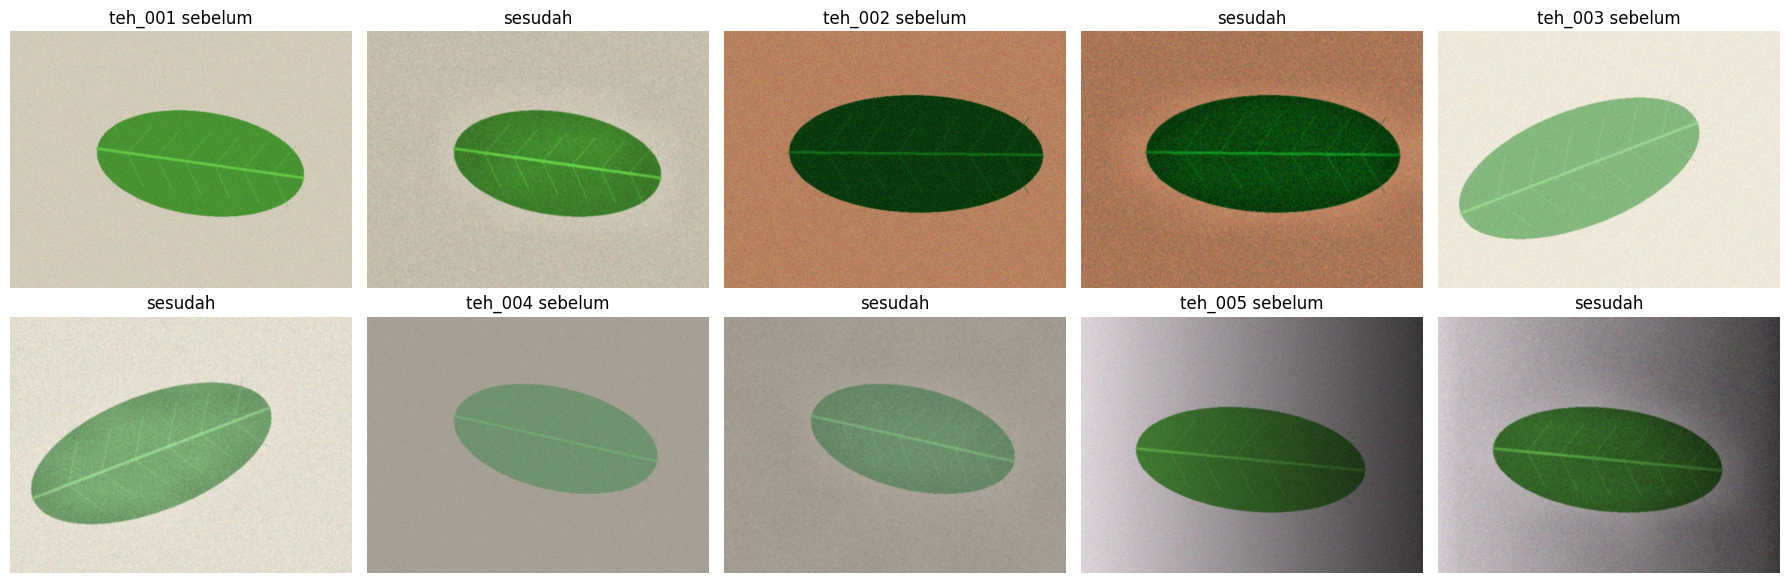

In [4]:
r = []
for _, d in label[label.kelas == "sehat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}"); a = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    o = praproses(im, final); dalam = cv2.erode(a, np.ones((15, 15), np.uint8)) > 0
    s0, s1 = im[:, :, KANAL][dalam].std(), o[:, :, KANAL][dalam].std()
    z = (o[:, :, KANAL].astype(float) - o[:, :, KANAL][dalam].mean()) / (s1 + 1e-6)
    r.append([d.kondisi_cahaya, s0, s1, int((np.abs(z[dalam]) > 4).sum())])
uji = pd.DataFrame(r, columns=["kondisi", "std_sebelum", "std_sesudah", "piksel_>4sigma"]).groupby("kondisi").mean().loc[URUT].round(2)
print(uji); uji.to_csv("../hasil/b5_uji_sehat.csv")
# panel sebelum dan sesudah untuk satu citra per kondisi (kelas sehat: teh_001 s.d. teh_005)
daftar, judul = [], []
for i in range(1, 6):
    im = baca(f"../data/sintetis/citra/teh_{i:03d}.png"); daftar += [im, praproses(im, final)]; judul += [f"teh_{i:03d} sebelum", "sesudah"]
tampil(daftar, judul, baris=2, ukuran=(18, 6)); plt.savefig("../hasil/b5_panel_sehat.png"); plt.show()

### Langkah 5.4 Justifikasi (Tabel 13)

| Langkah | Parameter final | Alasan dan bukti | Risiko bila salah atur |
|---|---|---|---|
| 1. Ubah ukuran | lebar 640, `INTER_AREA` | Mengurangi 39 kali operasi per penapis (P4.6) dan cukup cepat untuk ponsel; memenuhi kebutuhan 4. Syarat jarak ≤ 22,9 cm agar bercak tetap ≥ 10 piksel (2.1 d) | Terlalu kecil: bercak ringan hilang (Tabel sampling, P2.5); terlalu besar: lambat |
| 2. Koreksi gamma | 1,0 (tidak dipakai) | Gamma tetap tidak menolong semua kondisi (gamma 0,5 menurunkan KB bayangan, Tabel 10; gamma 0,6 pada teh_042 menurunkan KB gelap dari 3,41 ke 2,83); kondisi gelap/terang lebih baik ditangani aturan adaptif (P3.5) | Gamma ekstrem membuat daun sehat pucat atau gelap dan mengubah kesan warna |
| 3. CLAHE kanal V | clip 1,0; tile 8 | KB rata-rata 10,47 (vs 9,28 untuk clip 2); KB naik di kelima kondisi (Tabel 12); kanal V menjaga Hue (P3.4) | Clip besar atau tile kecil menguatkan derau dan tulang daun menjadi bintik mirip bercak (P3.6); pada kondisi terang clip 2 justru menurunkan KB |
| 4. Redam derau | median, kernel 3 | Median 3 terbaik untuk garam-merica dan cepat (Tabel 11); kernel kecil menjaga bercak ringan (P4.4: dI tetap 28 pada kernel 3) | Kernel ≥ 9 menghapus bercak ringan; rerata/Gaussian mengaburkan tepi bercak |
| 5. Tajamkan | tidak dipakai (k = 0) | Derau sudah ditekan; menajamkan dapat memperkuat sisa derau, dan urutan memengaruhi hasil untuk median (P4.5) | Penajaman berlebihan menimbulkan halo dan titik terang palsu |

Diagram rangkaian dengan parameter final dibuat pada sel berikut.

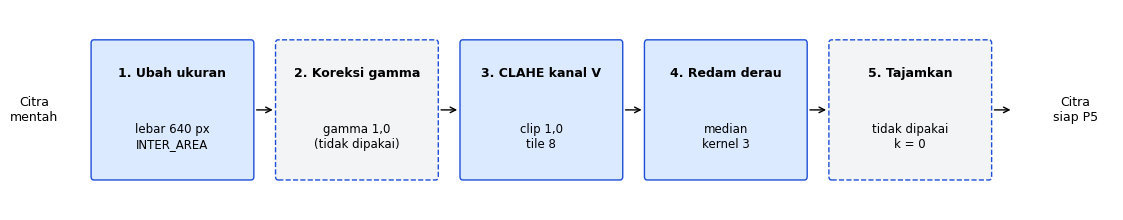

In [5]:
langkah = [("1. Ubah ukuran", "lebar 640 px\nINTER_AREA"), ("2. Koreksi gamma", "gamma 1,0\n(tidak dipakai)"),
           ("3. CLAHE kanal V", "clip 1,0\ntile 8"), ("4. Redam derau", "median\nkernel 3"), ("5. Tajamkan", "tidak dipakai\nk = 0")]
fig, ax = plt.subplots(figsize=(14, 2.6)); ax.axis("off"); ax.set_xlim(0, 20); ax.set_ylim(0, 3)
ax.text(0.1, 1.5, "Citra\nmentah", ha="center", va="center", fontsize=9)
for i, (a_, b_) in enumerate(langkah):
    x = 1.2 + i * 3.4
    ax.add_patch(FancyBboxPatch((x, 0.5), 2.9, 2, boxstyle="round,pad=0.05", fc="#dbeafe" if i not in (1, 4) else "#f3f4f6", ec="#1d4ed8", ls="-" if i not in (1, 4) else "--"))
    ax.text(x + 1.45, 2.0, a_, ha="center", fontsize=9, fontweight="bold"); ax.text(x + 1.45, 1.1, b_, ha="center", va="center", fontsize=8.5)
    ax.annotate("", xy=(x + 3.35, 1.5), xytext=(x + 2.95, 1.5), arrowprops=dict(arrowstyle="->"))
ax.text(19.3, 1.5, "Citra\nsiap P5", ha="center", va="center", fontsize=9)
plt.savefig("../hasil/b5_diagram_final.png", dpi=150, bbox_inches="tight"); plt.show()

### Langkah 5.5 Reprodusibilitas (jalankan sendiri)
1. *Runtime > Restart session and run all* sampai tidak ada galat.
2. Perbarui `README.md`: cara menjalankan, SEED **1025**, ringkasan hasil (rujuk tabel di atas).
3. Di terminal repository:
```bash
git add . && git commit -m "B5: praproses terintegrasi dan evaluasi"
git tag v0.1-praproses && git push && git push --tags
```

### Jawaban Pertanyaan Analisis Bagian 5

**P5.1 KB naik di semua kondisi?** Ya, dengan parameter final (CLAHE clip 1, median 3, kanal R): normal 9,92 menjadi 13,31 (+34,3%), gelap 8,99 menjadi 16,77 (+86,6%), terang 6,39 menjadi 8,49 (+32,7%), kontras rendah 3,50 menjadi 6,21 (+77,4%), bayangan 4,53 menjadi 7,58 (+67,3%). Rata-rata 6,67 menjadi 10,47. Kondisi tersulit adalah **kontras rendah** (KB sesudah terendah, 6,21) lalu **bayangan** (7,58). Pada kontras rendah, rentang intensitas daun dan bercak dimampatkan (f = 0,35 f + 95) sehingga selisih bercak-daun kecil dibanding derau; pada bayangan, gradasi cahaya membuat rerata daun berbeda antar-sisi sehingga simpangan baku daun besar. Catatan: sebagian kenaikan berasal dari median yang menurunkan derau (penyebut KB mengecil), bukan hanya dari CLAHE (tanpa CLAHE KB rata-rata sudah 10,85).

**P5.2 KB turun?** Pada parameter contoh (CLAHE clip 2, median 3) KB kondisi **terang** turun dari 6,39 menjadi 6,14 (-4%). Sebab: citra terang punya 75% piksel di atas 205, mendekati jenuh; CLAHE clip 2 menaikkan kontras lokal derau dan variasi daun sehat (penyebut membesar), sehingga rasio KB turun. Perbaikan: pilih parameter otomatis dari statistik histogram. Aturan pada P3.5 (CLAHE hanya bila bayangan atau gelap, tanpa CLAHE bila terang atau normal) menghasilkan KB terang 10,61 dan rerata keseluruhan 11,38. Pada parameter final (clip 1) tidak ada kondisi yang turun.

**P5.3 Bercak palsu?** Pada 20 citra sehat, simpangan baku kanal R di area daun justru **turun** di semua kondisi (normal 11,13 menjadi 7,27; gelap 10,13 menjadi 5,64; terang 10,15 menjadi 7,59; kontras rendah 9,88 menjadi 5,94; bayangan 12,40 menjadi 8,44), jadi keragaman daun sehat tidak membengkak. Jumlah piksel yang menyimpang lebih dari 4σ paling besar pada kondisi **normal** (sekitar 690 piksel) dan **terang** (sekitar 480); ini adalah tulang daun yang memang lebih terang (digambar 1,35 kali lebih terang). Pada panel `b5_panel_sehat.png` yang saya periksa, tidak muncul bintik terang baru pada daun sehat; yang tampak hanya tulang dan cabang daun menjadi lebih tegas. *(Periksa panel milikmu sendiri untuk memastikan.)* Risiko: tulang daun terang pada kondisi normal/terang dapat dikira bercak pada tahap segmentasi dan menyebabkan daun sehat salah diklasifikasikan sebagai bercak ringan pada P11; ini perlu diwaspadai dengan fitur bentuk (garis memanjang vs bulat).

**P5.4 Praproses yang sama untuk data latih dan uji.** Model mempelajari distribusi fitur dari citra yang sudah dipraproses. Jika data uji dipraproses berbeda (mis. tanpa CLAHE atau dengan ukuran lain), fitur uji bergeser dari fitur latih (*train-serving skew*), sehingga akurasi pada uji tampak lebih rendah atau tidak mewakili kondisi nyata, dan perbandingan antar-model tidak adil. Parameter juga tidak boleh dipilih dengan melihat data uji (kebocoran data); itu sebabnya parameter disimpan di JSON dan dipakai ulang tanpa diubah.

**P5.5 Nilai AIK.**
- **Jujur:** semua angka dilaporkan apa adanya dari keluaran kode dengan SEED sendiri, termasuk penurunan KB pada kondisi terang (parameter contoh) dan keterbatasan KB (P2.4, P4.4); dataset sintetis dinyatakan tidak mewakili foto nyata; bagian yang dibantu AI dicantumkan di refleksi.
- **Amanah:** EXIF dihapus, tidak ada wajah atau lokasi di repository; repository privat, SEED, versi pustaka, parameter JSON, dan tag git dicatat agar hasil dapat ditelusuri dan diulang; keputusan akhir mutu tetap di tangan petugas.

---
## Selesai: daftar periksa sebelum mengumpulkan
- [ ] Notebook jalan penuh (*Restart and run all*) tanpa galat
- [ ] Kolom "Pengamatan visual" Tabel 10, dan pengamatan panel (sampling, uji sehat) diisi dari penglihatanmu sendiri
- [ ] Problem statement ditulis ulang dengan kalimatmu sendiri
- [ ] Lembar hitung manual (Bagian 2, 3, 4) ditulis tangan atau dilampirkan
- [ ] Laporan PDF (Arial 11, spasi 1,5), slide PPTX 10 sampai 12 slide, ZIP kode, tautan GitHub dengan tag `v0.1-praproses`
- [ ] Cantumkan di refleksi bagian yang dibantu AI